# Day 47 - Capstone Project : Predictive Maintenance - Failuer Prediction Manufactory Machine

Selamat datang di **proyek capstone**! Ini adalah salah satu studi kasus paling bernilai di dunia industri:

**Predictive Maintenance** (perawatan prediktif).
Alih-alih menunggu mesin rusak (*reactive*) atau merawat terjadwal walau belum perlu (*preventive*), Saya akan memakai **data sensor** untuk memprediksi kapan sebuah mesin berisiko gagal — sehingga teknisi bisa bertindak **sebelum** kerusakan terjadi.

> 🎯 **Tujuan Pembelajaran**
> - Memahami konteks bisnis predictive maintenance & biaya *downtime*.
> - EDA data sensor mesin (suhu, putaran, torsi, keausan alat).
> - **Feature engineering** dari pengetahuan domain (selisih suhu, daya mekanik).
> - Menangani **data tidak seimbang** dengan `class_weight`.
> - Melatih & membandingkan **RandomForest** dan **GradientBoosting**.
> - Fokus pada **precision/recall** karena biaya kesalahan tidak simetris.
> - Menerjemahkan *feature importance* menjadi **rekomendasi perawatan**.

## About Dataset

Saya akan memakai **Machine Predictive Maintenance Classification** — dataset sintetis yang dirancang menyerupai data sensor mesin manufaktur nyata (10.000 unit produksi).

- **Sumber:** [Kaggle — shivamb/machine-predictive-maintenance-classification](https://www.kaggle.com/datasets/shivamb/machine-predictive-maintenance-classification)
- **Jumlah data:** 10.000 baris × 10 kolom

| Kolom | Arti |
|-------|------|
| `UDI` | Nomor identifikasi unik (dibuang — bukan fitur) |
| `Product ID` | Kode produk (dibuang — bukan fitur) |
| `Type` | Kualitas/varian produk: **L** (Low), **M** (Medium), **H** (High) |
| `Air temperature [K]` | Suhu udara sekitar (Kelvin) |
| `Process temperature [K]` | Suhu proses mesin (Kelvin) |
| `Rotational speed [rpm]` | Kecepatan putar (rotasi per menit) |
| `Torque [Nm]` | Torsi (Newton-meter) |
| `Tool wear [min]` | Lama keausan alat (menit) |
| `Target` | **Label kita** → 1 = mesin gagal, 0 = normal |
| `Failure Type` | Jenis kegagalan (TIDAK dipakai sebagai fitur → bocor!) |

> ⚠️ **Penting (kebocoran data):** kolom `Failure Type` adalah *konsekuensi* dari
> kegagalan, bukan penyebab yang bisa diukur sebelum kegagalan. Memakainya sebagai
> fitur akan "membocorkan" jawaban. Kita memakai `Target` sebagai label dan membuang
> `Failure Type`, `UDI`, serta `Product ID`.

## Import Library

- **pandas / numpy** → manipulasi data & operasi numerik.
- **matplotlib / seaborn** → visualisasi.
- **scikit-learn** → preprocessing, model (RandomForest, GradientBoosting), dan metrik evaluasi.

In [2]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

In [3]:
from sklearn.preprocessing import StandardScaler

from sklearn.model_selection import train_test_split

from sklearn.ensemble import RandomForestClassifier, GradientBoostingClassifier
from sklearn.metrics import (classification_report, confusion_matrix,
                             roc_curve, roc_auc_score, f1_score,
                             precision_score, recall_score, accuracy_score,
                             RocCurveDisplay)

## Import Dataset

In [4]:
!pip install kaggle
!mkdir ~/.kaggle
!cp kaggle.json ~/.kaggle/
!chmod 600 ~/.kaggle/kaggle.json
!kaggle datasets download -d shivamb/machine-predictive-maintenance-classification
!unzip machine-predictive-maintenance-classification.zip

cp: cannot stat 'kaggle.json': No such file or directory
chmod: cannot access '/root/.kaggle/kaggle.json': No such file or directory
Dataset URL: https://www.kaggle.com/datasets/shivamb/machine-predictive-maintenance-classification
License(s): CC0-1.0
100% 137k/137k [00:00<00:00, 77.3MB/s]

Archive:  machine-predictive-maintenance-classification.zip
  inflating: predictive_maintenance.csv  


## Early Exploration

In [7]:
df = pd.read_csv('predictive_maintenance.csv')
df.head()

,UDI,Product ID,Type,Air temperature [K],Process temperature [K],Rotational speed [rpm],Torque [Nm],Tool wear [min],Target,Failure Type
0,1,M14860,M,298.1,308.6,1551,42.8,0,0,No Failure
1,2,L47181,L,298.2,308.7,1408,46.3,3,0,No Failure
2,3,L47182,L,298.1,308.5,1498,49.4,5,0,No Failure
3,4,L47183,L,298.2,308.6,1433,39.5,7,0,No Failure
4,5,L47184,L,298.2,308.7,1408,40.0,9,0,No Failure


📋 Struktur Kolom

Sebelum masuk ke barisnya, mari pahami atributnya:

- > UDI / Index: Nomor unik baris.

- > Product ID: Kode produk unik (mengandung huruf kualitas mesin dan nomor seri).

- > Type: Varian kualitas mesin ( L = Low [50% produk], M = Medium [30% produk], H = High [20% produk]).

- > Air temperature [K]: Suhu udara sekitar mesin dalam Kelvin (dikonversi dari suhu konstan sekitar 298K / ~25°C).

- > Process temperature [K]: Suhu operasional proses mesin dalam Kelvin.

- > Rotational speed [rpm]: Kecepatan putar poros/spindle dalam satuan RPM.

- > Torque [Nm]: Torsi atau gaya puntir yang dihasilkan mesin.

- > Tool wear [min]: Akumulasi waktu keausan alat potong (cutting tool) dalam menit.

- > Target: Status kegagalan (0 = Normal/Tidak Gagal, 1 = Gagal).

- > Failure Type: Jenis spesifik kegagalan (jika terjadi).

In [11]:
df.info()

print(f'Jumlah baris: {df.shape[0]}')
print(f'Jumlah kolom: {df.shape[1]}')

print(f'Missing Value: {df.isnull().sum().sum()}')
print(f'Duplicate Data: {df.duplicated().sum()}')

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 10000 entries, 0 to 9999
Data columns (total 10 columns):
 #   Column                   Non-Null Count  Dtype  
---  ------                   --------------  -----  
 0   UDI                      10000 non-null  int64  
 1   Product ID               10000 non-null  object 
 2   Type                     10000 non-null  object 
 3   Air temperature [K]      10000 non-null  float64
 4   Process temperature [K]  10000 non-null  float64
 5   Rotational speed [rpm]   10000 non-null  int64  
 6   Torque [Nm]              10000 non-null  float64
 7   Tool wear [min]          10000 non-null  int64  
 8   Target                   10000 non-null  int64  
 9   Failure Type             10000 non-null  object 
dtypes: float64(3), int64(4), object(3)
memory usage: 781.4+ KB
Jumlah baris: 10000
Jumlah kolom: 10
Missing Value: 0
Duplicate Data: 0


**Interpretasi:**

Berikut adalah interpretasi diringkas menjadi 5 poin utama:

1. **Ukuran Dataset Besar:** Dataset ini memiliki 10.000 baris data operasional mesin, memberikan sampel yang cukup luas dan representatif untuk melatih model *machine learning*.
2. **Kualitas Data Sangat Bersih:** Terdapat 0 *missing value* dan 0 data duplikat, sehingga data sudah bersih dan siap langsung masuk ke tahap *preprocessing* atau *feature engineering*.
3. **Komposisi Kolom:** Memiliki total 10 kolom yang terbagi menjadi 3 kolom kategorikal (teks/kategori) dan 7 kolom numerikal (angka/sensor).
4. **Parameter Fisik Komprehensif:** Kolom numerikal mencakup data sensor penting seperti suhu udara, suhu proses, kecepatan putar (*rpm*), torsi (*Nm*), dan keausan alat (*tool wear*).
5. **Siap untuk Klasifikasi:** Kolom `Target` dan `Failure Type` berfungsi sebagai label target untuk mendeteksi apakah suatu kondisi mesin berstatus normal atau mengalami kegagalan.

---

In [12]:
df.describe().T

,count,mean,std,min,25%,50%,75%,max
UDI,10000.0,5000.50000,2886.895680,1.0,2500.75,5000.5,7500.25,10000.0
Air temperature [K],10000.0,300.00493,2.000259,295.3,298.30,300.1,301.50,304.5
Process temperature [K],10000.0,310.00556,1.483734,305.7,308.80,310.1,311.10,313.8
Rotational speed [rpm],10000.0,1538.77610,179.284096,1168.0,1423.00,1503.0,1612.00,2886.0
Torque [Nm],10000.0,39.98691,9.968934,3.8,33.20,40.1,46.80,76.6
Tool wear [min],10000.0,107.95100,63.654147,0.0,53.00,108.0,162.00,253.0
Target,10000.0,0.03390,0.180981,0.0,0.00,0.0,0.00,1.0


Berikut adalah interpretasi ringkas dari tabel *statistical summary* (deskripsi statistik) di atas:

1. **Ukuran Data Konsisten:** Semua 10 kolom memiliki 10.000 data valid (`count` = 10000.0) tanpa ada yang kosong.
2. **Suhu Relatif Stabil:** Suhu udara rata-rata ada di sekitar 300K (27°C) dan suhu proses di 310K (37°C), dengan rentang nilai yang tidak terlalu jauh (minimum dan maksimum rapat).
3. **Kecepatan & Torsi Bervariasi:** Putaran mesin rata-rata 1.538 RPM (maksimal hampir 2.900 RPM) dan torsi rata-rata 40 Nm dengan titik tertinggi mencapai 76,6 Nm.
4. **Keausan Alat Beragam:** Rata-rata durasi penggunaan alat (*tool wear*) adalah 107 menit, dengan titik maksimum mencapai 253 menit.
5. **Data Sangat Tidak Seimbang (*Imbalanced*):** Nilai rata-rata kolom `Target` sangat kecil yaitu **0.0339** (hanya sekitar 3,39% dari total 10.000 data yang berstatus gagal/1), yang menunjukkan kasus kegagalan mesin sangat langka dibanding kondisi normal.

---

## Seberapa sering Mesin Gagal ? ( Cek Imbalanced )

Pada data kegagalan industri, kejadian gagal biasanya **langka**. Mari lihat sebaran `Target`.

In [13]:
target_counts = df['Target'].value_counts()
print(f'Jumlah mesin normal: {target_counts[0]}')
print(f'Jumlah mesin gagal: {target_counts[1]} ')

Jumlah mesin normal: 9661
Jumlah mesin gagal: 339 


In [14]:
ratio_failure = df['Target'].mean()*100
print(f'Rata-rata mesin gagal: {ratio_failure:.2f}%')

Rata-rata mesin gagal: 3.39%


**Interpretasi:**

Berikut adalah interpretasi sederhana dari data distribusi target tersebut:

1. **Mayoritas Kondisi Normal:** Dari total 10.000 data mesin, sebanyak **9.661 mesin (96,61%)** berada dalam kondisi normal dan tidak mengalami kerusakan.
2. **Kasus Kegagalan Sangat Sedikit:** Hanya ada **339 mesin (3,39%)** yang tercatat mengalami kegagalan (`Target = 1`).
3. **Masalah *Imbalanced Data*:** Kondisi ini menunjukkan bahwa dataset kita **sangat tidak seimbang (*imbalanced*)**. Model *machine learning* nantinya bisa cenderung menebak "normal" terus karena jumlah data normal jauh lebih mendominasi, sehingga teknik khusus seperti *class weight* atau *resampling* sangat diperlukan agar model peka mendeteksi mesin yang benar-benar akan gagal.
4. Menggunakan `class_weight="balanced"`

---

## Exploratory Data Analysis

Saya akan menggali pola sensor, terutama perbedaan antara mesin **normal** vs **gagal**.

### a) Distribusi tiap sensor ( Histogram )

In [15]:
feature_sensor = ['Air temperature [K]',
                  'Process temperature [K]',
                  'Rotational speed [rpm]',
                  'Torque [Nm]',
                  'Tool wear [min]']

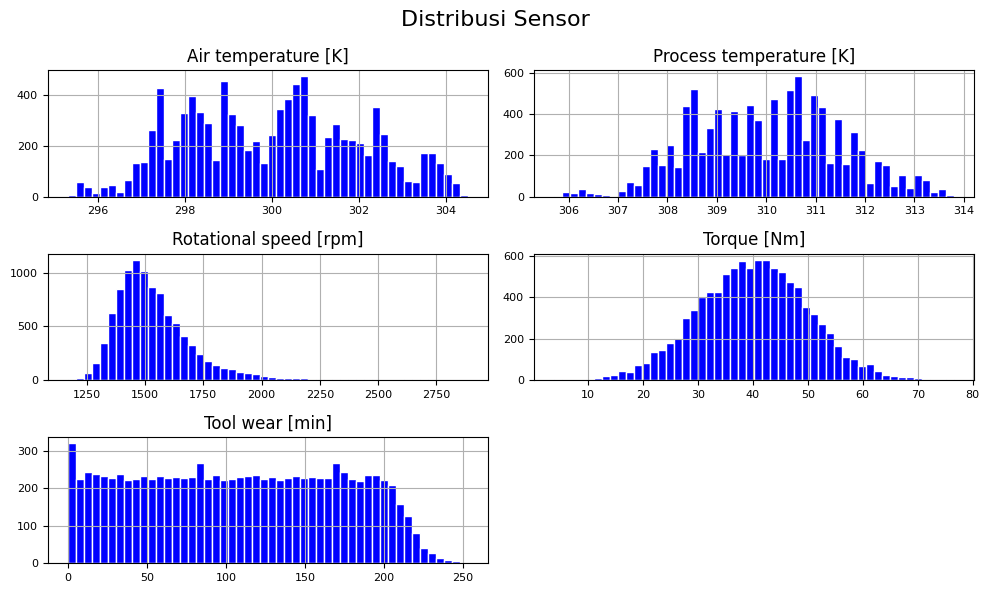

In [24]:
from IPython.terminal.embed import EmbeddedMagics
df[feature_sensor].hist(bins=50,
                        figsize=(10, 6),
                        xlabelsize=8,
                        edgecolor="white",
                        ylabelsize=8,
                        color='blue',
                        )

plt.suptitle('Distribusi Sensor', fontsize=16)
plt.tight_layout()
plt.show()

**Interpretasi:**


Berikut adalah interpretasi sederhana dan terstruktur untuk grafik **Distribusi Sensor** di atas:

* **Air temperature [K] & Process temperature [K]:**
  - Kedua grafik suhu menunjukkan distribusi yang mirip kurva normal (lonceng) yang agak bergelombang, dengan suhu udara terkonsentrasi di sekitar 298–302 K dan suhu proses di sekitar 308–312 K.


* **Rotational speed [rpm]:**
  -  Distribusi kecepatan putar berbentuk *right-skewed* (cenderung menceng ke kanan), di mana mayoritas mesin beroperasi pada kisaran 1.400–1.500 RPM, namun ada beberapa yang mencapai kecepatan tinggi hingga mendekati 3.000 RPM.


* **Torque [Nm]:**
  - Grafik torsi menunjukkan bentuk distribusi normal yang sangat simetris, dengan titik tengah (puncak) berada di sekitar angka 40 Nm.


* **Tool wear [min]:**
  - Distribusi keausan alat potong terlihat cukup merata (seragam) dari rentang 0 hingga sekitar 200 menit, sebelum akhirnya mengalami penurunan tajam pada durasi di atas 200 menit.

### b) Pebandingan Sensor: Normal Machine vs Failure

/tmp/ipykernel_531/1196246372.py:4: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.boxplot(data=df, x='Target', y=col, ax=ax,
/tmp/ipykernel_531/1196246372.py:8: UserWarning: No artists with labels found to put in legend.  Note that artists whose label start with an underscore are ignored when legend() is called with no argument.
  ax.legend()
/tmp/ipykernel_531/1196246372.py:4: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.boxplot(data=df, x='Target', y=col, ax=ax,
/tmp/ipykernel_531/1196246372.py:8: UserWarning: No artists with labels found to put in legend.  Note that artists whose label start with an underscore are ignored when legend() is called with no argument.
  ax.legend()
/tmp/ipykernel_531/11962

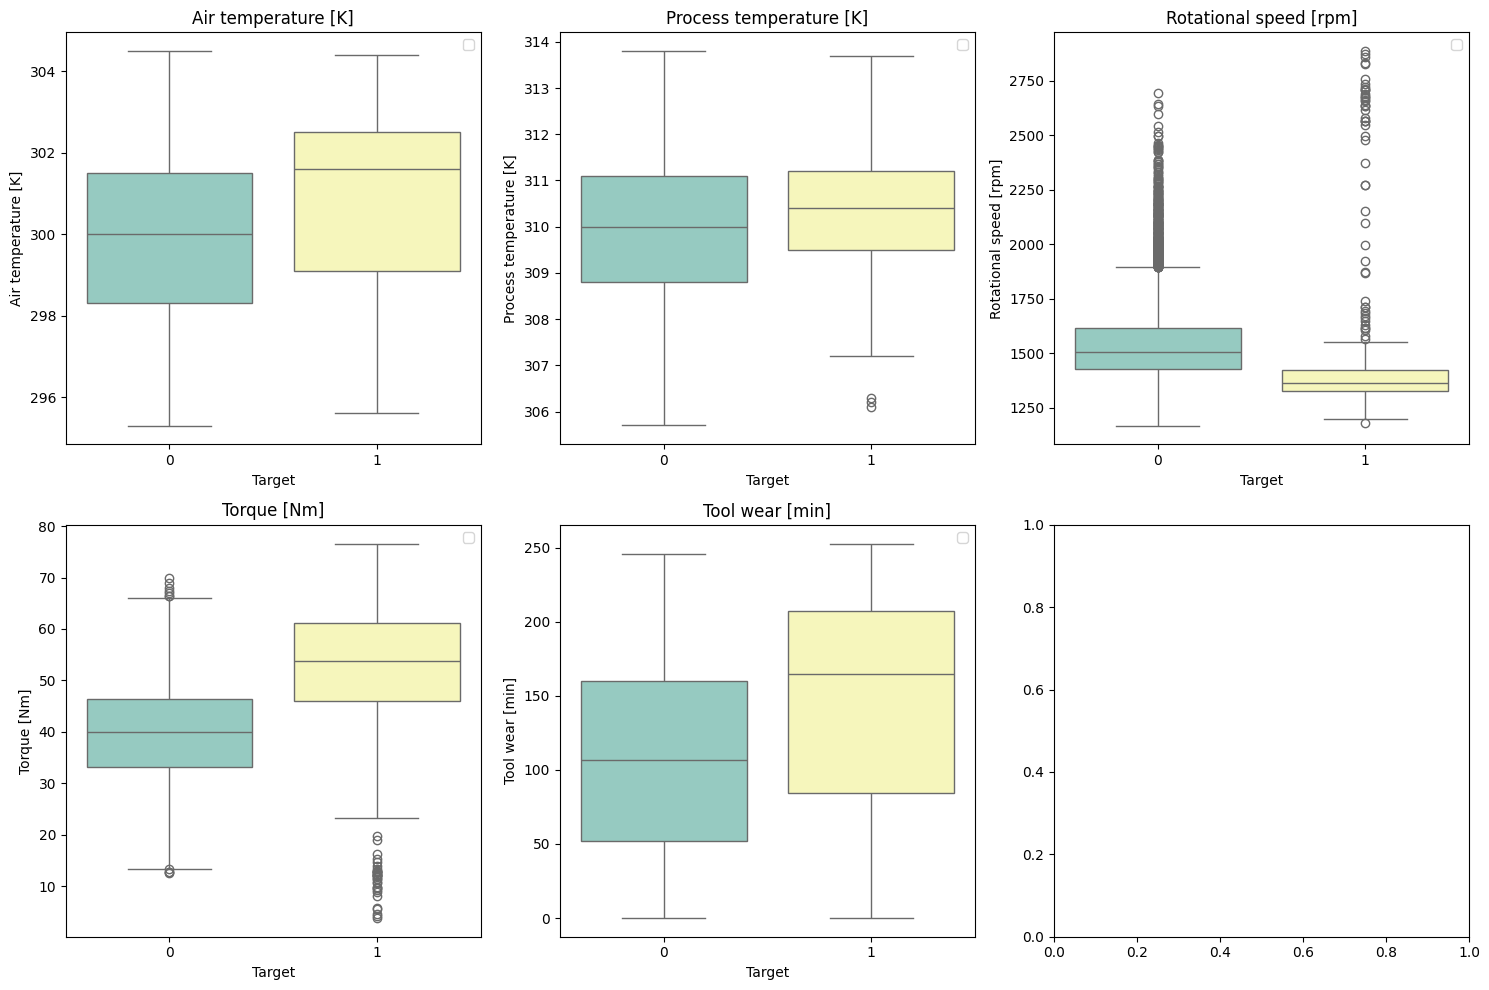

In [28]:
fig, axes = plt.subplots(2,3, figsize=(15,10))

for ax, col in zip(axes.ravel(), feature_sensor):
    sns.boxplot(data=df, x='Target', y=col, ax=ax,
                palette="Set3")
    ax.set_xlabel('Target')
    ax.set_ylabel(col)
    ax.legend()
    ax.set_title(col)

plt.tight_layout()
plt.show()

**Interpretasi:**

Berikut adalah interpretasi sederhana dari grafik *box plot* perbandingan sensor terhadap Target (0 = Normal, 1 = Gagal):

* **Suhu (`Air` & `Process temperature`):**
  - Mesin yang mengalami kegagalan (Target 1, warna kuning) cenderung memiliki median suhu yang sedikit lebih tinggi dibandingkan mesin normal (Target 0, warna hijau).

* **Kecepatan Putar (`Rotational speed`):**
  - Mesin gagal justru cenderung berputar pada kecepatan yang lebih rendah secara median, namun memiliki banyak titik *outlier* (pencilan) di kecepatan tinggi.

* **Torsi (`Torque`):**
  - Mesin yang mengalami kegagalan memiliki tingkat torsi (*torque*) yang **jauh lebih tinggi** secara signifikan dibandingkan mesin normal.

* **Keausan Alat (`Tool wear`):**
  - Durasi keausan alat pada mesin gagal cenderung lebih tinggi, dengan median yang mengindikasikan alat sudah lebih lama digunakan.

### c) Correlation Numerical Feature

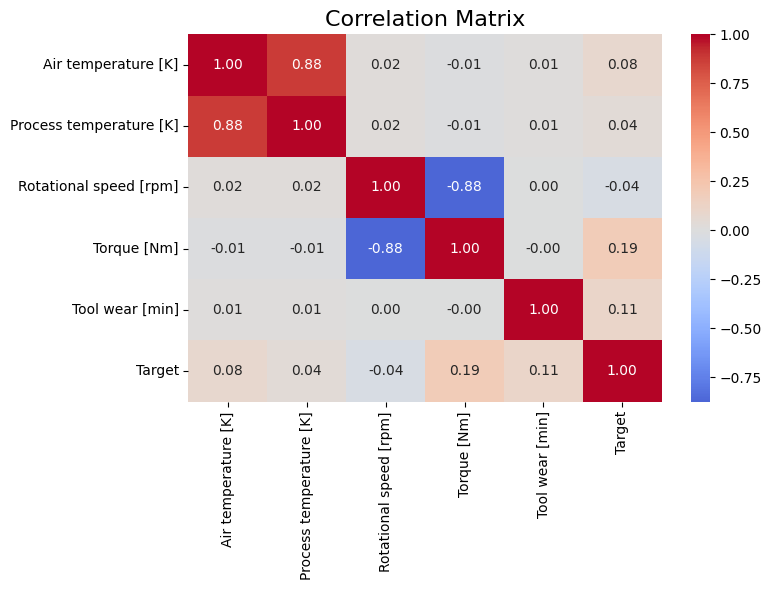

In [30]:
plt.figure(figsize=(8,6))

sns.heatmap(df[feature_sensor + ["Target"]].corr(),
            annot=True, fmt=".2f", cmap="coolwarm",
            center=0)

plt.title("Correlation Matrix", fontsize=16)
plt.tight_layout()
plt.show()

**Interpretasi:**

Berikut adalah interpretasi sederhana dari matriks korelasi (*Correlation Matrix*) di atas:

* **Suhu Saling Berkaitan Kuat:**
  - *Air temperature* dan *Process temperature* memiliki korelasi positif yang sangat tinggi (0.88), artinya kenaikan suhu udara hampir selalu sejalan dengan kenaikan suhu proses.


* **Kecepatan dan Torsi Berbanding Terbalik:**
  - *Rotational speed* dan *Torque* memiliki korelasi negatif yang kuat (-0.88), yang berarti semakin cepat mesin berputar, umumnya torsi yang dihasilkan akan semakin rendah.


* **Korelasi dengan Target:**
  - Sebagian besar fitur sensor memiliki korelasi linear yang relatif lemah terhadap *Target* (nilai di bawah 0.20), di mana *Torque* (0.19) dan *Tool wear* (0.11) menunjukkan hubungan paling besar terhadap potensi kegagalan mesin.

### d) Failure Level each Type of Product (Bar)

In [32]:
fail_by_type = df.groupby('Type')['Target'].mean().mul(100).sort_values(ascending=False)

fail_by_type

,Target
Type,
L,3.916667
M,2.769436
H,2.093719


(array([0, 1, 2]), [Text(0, 0, 'L'), Text(1, 0, 'M'), Text(2, 0, 'H')])

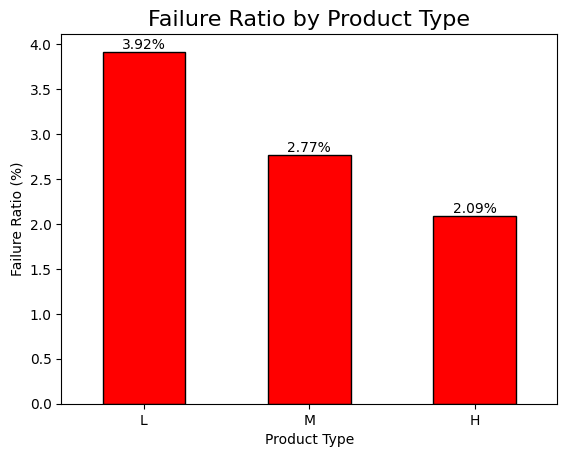

In [38]:
ax = fail_by_type.plot(kind="bar",
                       color="red",
                       edgecolor="black")

plt.title("Failure Ratio by Product Type", fontsize=16)
plt.xlabel("Product Type")
plt.ylabel("Failure Ratio (%)")
for i in ax.patches:
    ax.annotate(f"{i.get_height():.2f}%",
                (i.get_x() + i.get_width() / 2, i.get_height()),
                ha="center", va="center",
                size=10, xytext=(0, 5),
                textcoords="offset points")
plt.xticks(rotation=0)

**Interpretasi:**

Berikut adalah interpretasi sederhana dari grafik **Failure Ratio by Product Type** di atas:

* **Tipe L (Low Quality):**
  - Memiliki rasio kegagalan tertinggi, yaitu **3.92%**.

* **Tipe M (Medium Quality):**
  - Berada di posisi menengah dengan rasio kegagalan sebesar **2.77%**.

* **Tipe H (High Quality):**
  - Memiliki rasio kegagalan paling rendah, yakni **2.09%**.

* **Kesimpulan:**
  - Terdapat pola yang jelas bahwa produk dengan kelas kualitas lebih rendah (*Low*) cenderung memiliki risiko kegagalan yang lebih tinggi dibandingkan kualitas menengah (*Medium*) dan tinggi (*High*).

---


## Feature Engineering

Inilah nilai tambah seorang data scientist: membuat fitur baru dari pemahaman fisika mesin.

1. **`temp_diff`** = Suhu proses − Suhu udara → seberapa banyak panas yang dihasilkan
   proses. Selisih kecil bisa berarti pendinginan buruk / beban abnormal.
2. **`power`** = Torsi × kecepatan sudut. Daya mekanik (Watt) =
   $\tau \times \omega$, dengan $\omega = \text{rpm} \times 2\pi / 60$.
   Daya berlebih membebani mesin.
3. **One-hot encoding** untuk `Type` (kategori) menjadi kolom 0/1.

In [39]:
data = df.copy()

In [40]:
#Create new Feature
data['temp_diff'] = data['Process temperature [K]'] - data['Air temperature [K]']
data['power'] = data['Torque [Nm]'] * data['Rotational speed [rpm]']

In [41]:
#Drop Kolom yang tidak dijadikan data untuk modeling [ID dan Kebocoran]
data = data.drop(['UDI', 'Product ID', 'Failure Type'], axis=1, inplace=True)

In [45]:
# Salin kembali data dari df untuk mereset variabel 'data' yang sempat menjadi None
data = df.copy()

# Buat fitur baru
data['temp_diff'] = data['Process temperature [K]'] - data['Air temperature [K]']
data['power'] = data['Torque [Nm]'] * data['Rotational speed [rpm]']

# Drop kolom (tanpa menyimpan hasil dari inplace=True)
data = data.drop(['UDI', 'Product ID', 'Failure Type'], axis=1)

# Encode Data Kategorikal dengan One Hot Encoding
data = pd.get_dummies(data, columns=["Type"], prefix="Type")
data.head()

,Air temperature [K],Process temperature [K],Rotational speed [rpm],Torque [Nm],Tool wear [min],Target,temp_diff,power,Type_H,Type_L,Type_M
0,298.1,308.6,1551,42.8,0,0,10.5,66382.8,False,False,True
1,298.2,308.7,1408,46.3,3,0,10.5,65190.4,False,True,False
2,298.1,308.5,1498,49.4,5,0,10.4,74001.2,False,True,False
3,298.2,308.6,1433,39.5,7,0,10.4,56603.5,False,True,False
4,298.2,308.7,1408,40.0,9,0,10.5,56320.0,False,True,False


In [46]:
print("Kolom setelah feature engineering:")
print(list(data.columns))
data[["temp_diff", "power"]].describe()

Kolom setelah feature engineering:
['Air temperature [K]', 'Process temperature [K]', 'Rotational speed [rpm]', 'Torque [Nm]', 'Tool wear [min]', 'Target', 'temp_diff', 'power', 'Type_H', 'Type_L', 'Type_M']


,temp_diff,power
count,10000.000000,10000.000000
mean,10.000630,59967.147040
std,1.001094,10193.093881
min,7.600000,10966.800000
25%,9.300000,53105.400000
50%,9.800000,59883.900000
75%,11.000000,66873.750000
max,12.100000,99980.400000


**Interpretasi:**


Berikut adalah interpretasi sederhana untuk **2 kolom baru** hasil *feature engineering* tersebut:

1. **`temp_diff` (Selisih Suhu):**
   -  Menunjukkan selisih antara suhu proses dan suhu udara sekitar (*Process temperature* - *Air temperature*).
   - Rata-rata selisih suhu berada di sekitar **10 Kelvin**, dengan nilai terendah 7.6 K dan tertinggi 12.1 K. Fitur ini sangat berguna untuk memantau efisiensi sistem pendingin mesin.


2. **`power` (Daya Mekanik):**
    -  Menggambarkan daya mekanik mesin yang dihitung dari kombinasi kecepatan putar (*rpm*) dan torsi (*Nm*).
    -  Nilai rata-rata daya adalah sekitar **59.967** (dengan rentang dari ~10.966 hingga maksimal ~99.980), membantu model mendeteksi anomali ketika mesin bekerja di luar kapasitas normalnya.


### Apakah Feature baru membedakan kegagalan?

/tmp/ipykernel_531/735021244.py:3: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.boxplot(data=data, x='Target', y='temp_diff', ax=axes[0],
/tmp/ipykernel_531/735021244.py:8: UserWarning: No artists with labels found to put in legend.  Note that artists whose label start with an underscore are ignored when legend() is called with no argument.
  axes[0].legend()
/tmp/ipykernel_531/735021244.py:12: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.boxplot(data=data, x='Target', y='power', ax=axes[1],
/tmp/ipykernel_531/735021244.py:16: UserWarning: No artists with labels found to put in legend.  Note that artists whose label start with an underscore are ignored when legend() is called with no argument.
  axes[1]

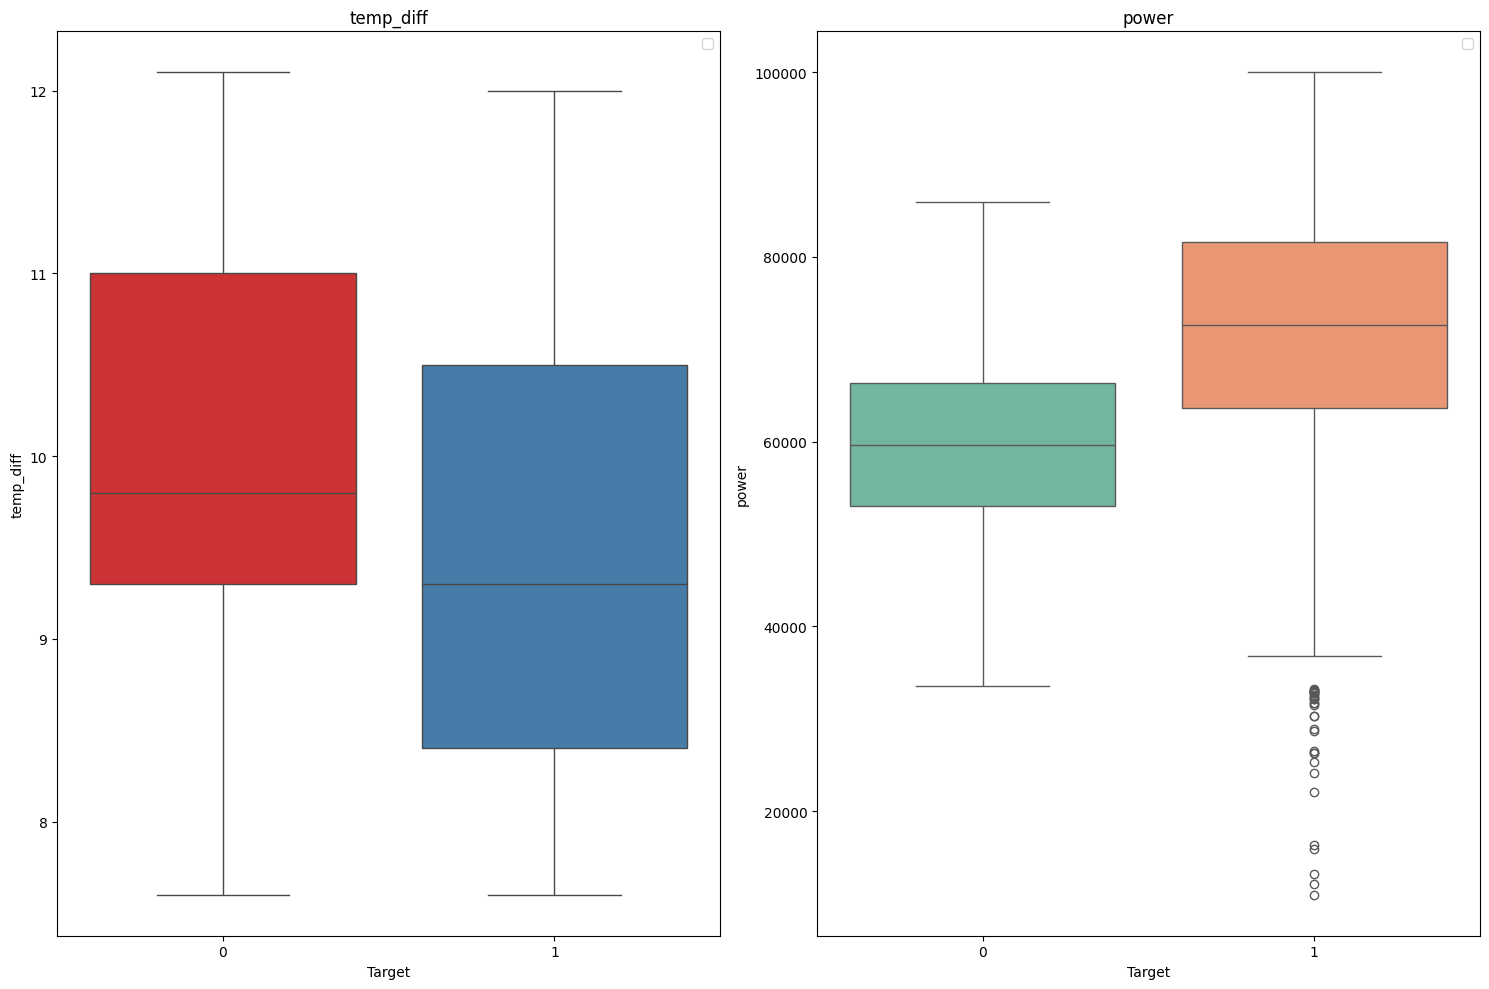

In [52]:
fig, axes = plt.subplots(1,2, figsize=(15,10))

sns.boxplot(data=data, x='Target', y='temp_diff', ax=axes[0],
            palette="Set1")

axes[0].set_xlabel('Target')
axes[0].set_ylabel('temp_diff')
axes[0].legend()
axes[0].set_title('temp_diff')


sns.boxplot(data=data, x='Target', y='power', ax=axes[1],
            palette="Set2")
axes[1].set_xlabel('Target')
axes[1].set_ylabel('power')
axes[1].legend()
axes[1].set_title('power')

plt.tight_layout()
plt.show()

Berikut adalah interpretasi sederhana dari grafik *box plot* kedua fitur baru tersebut terhadap *Target* (0 = Normal, 1 = Gagal):

* **`temp_diff` (Selisih Suhu):**
  - Mesin yang mengalami kegagalan (Target 1, warna biru) justru memiliki median selisih suhu yang **sedikit lebih rendah** atau mirip dibandingkan mesin normal (Target 0, warna merah). Namun, kedua kelompok memiliki rentang nilai maksimum yang sama (~12.1 K).



* **`power` (Daya Mekanik):**
  -  Mesin yang mengalami kegagalan (Target 1, warna oranye) menunjukkan tingkat daya mekanik yang **secara signifikan lebih tinggi** secara median dibandingkan mesin normal (Target 0, warna hijau toska).

  - Meskipun begitu, pada kelompok mesin gagal terdapat banyak titik *outlier* di bawah (daya sangat rendah), yang mengindikasikan adanya anomali mesin mati mendadak atau beban kerja yang tidak stabil sebelum kegagalan terjadi.





---

## Preprocessing ( Split & Scaling )




Saya akan pisahkan fitur (`X`) dan label (`y`), lalu bagi data latih/uji dengan **stratifikasi** agar proporsi mesin gagal terjaga di kedua set.

Saya juga akan melakukan *scaling* (berguna untuk konsistensi; tree-based tidak wajib, tapi tidak merugikan).

In [53]:
#Pisahkan feature dengan target
X = data.drop('Target', axis=1)
y = data['Target']

In [54]:
#Pisahlan Data latih dengan Test
X_train, X_test, y_train, y_test = train_test_split(X, y,
                                                    test_size=0.2,
                                                    random_state=42,
                                                    stratify=y)

In [55]:
#Standarisasi Data Latih
scaler = StandardScaler()
X_train_scaled = scaler.fit_transform(X_train)
X_test_scaled = scaler.transform(X_test)

In [56]:
#Tampilkan hasil
print(f'Jumlah data latih: {X_train.shape[0]}')
print(f'Jumlah data uji: {X_test.shape[0]}')

print(f'Jumlah data latih mesin normal: {y_train.value_counts()[0]}')
print(f'Jumlah data latih mesin gagal: {y_train.value_counts()[1]}')

Jumlah data latih: 8000
Jumlah data uji: 2000
Jumlah data latih mesin normal: 7729
Jumlah data latih mesin gagal: 271


**Interpretasi:**

Berikut adalah interpretasi sederhana dari pembagian data (*train-test split*) tersebut:

* **Pembagian Rasio 80:20:**
  - Total 10.000 data dibagi menjadi **8.000 data untuk pelatihan (*training*)** dan **2.000 data untuk pengujian (*testing*)**, yang merupakan proporsi standar dan ideal dalam *machine learning*.

* **Komposisi Data Latih yang Tidak Seimbang (*Imbalanced*):**
  - Dari 8.000 data latih, sebanyak **7.729 mesin berstatus normal**, sedangkan hanya ada **271 mesin yang gagal**.

* **Implikasi untuk Model:**
  - Karena jumlah data mesin gagal di data latih sangat sedikit (sekitar 3.39%), model *machine learning* wajib menggunakan penanganan khusus (seperti parameter `class_weight='balanced'` pada algoritma) agar model tidak mengabaikan kelas kegagalan dan benar-benar bisa belajar mengenali ciri-ciri mesin yang akan rusak.

## Modeling

Saya akan Melatih dua model ensemble yang kuat:
- **Random Forest** — banyak pohon keputusan yang "memilih" bersama. Kita set   `class_weight="balanced"` agar kelas gagal (yang langka) diberi bobot lebih besar.
- **Gradient Boosting** — pohon dibangun bertahap, tiap pohon memperbaiki kesalahan sebelumnya. (Tidak punya `class_weight`, tapi kuat menangkap pola halus.)

In [58]:
#Deklarasikan tiap model dan parameter masing masing
rf = RandomForestClassifier(n_estimators=300,
                            random_state=42,
                            class_weight="balanced",
                            n_jobs=1)



gb = GradientBoostingClassifier(n_estimators=300,
                                learning_rate=0.1,
                                max_depth=3,
                                random_state=42)

In [59]:
#Lakukan training model
rf.fit(X_train_scaled, y_train)
gb.fit(X_train_scaled, y_train)

print('Kedua model selesai di latih!')

Kedua model selesai di latih!


## Model Evaluation

Dalam predictive maintenance, dua jenis kesalahan tidak setara:

- **False Negative (FN):** mesin akan gagal tapi diprediksi normal → **mesin rusak mendadak**, biaya *downtime* sangat mahal. Kita ingin ini **sekecil mungkin** → artinya **recall tinggi**.

- **False Positive (FP):** mesin normal diprediksi gagal → teknisi memeriksa mesin yang sebenarnya sehat (boros biaya inspeksi, tapi jauh lebih murah daripada FN).

Mari bandingkan keduanya.

In [60]:
def eval_model(nama, model, x_te, y_te):
    y_pred_ = model.predict(x_te)
    return {
        "Model": nama,
        "Precision": precision_score(y_te, y_pred_),
        "Recall": recall_score(y_te, y_pred_),
        "F1": f1_score(y_te, y_pred_),
        "ROC-AUC": roc_auc_score(y_te, model.predict_proba(x_te)[:, 1]),
    }

In [62]:
result = pd.DataFrame([
    eval_model("Random Forest", rf, X_test_scaled, y_test),
    eval_model("Gradient Boosting", gb, X_test_scaled, y_test),
]).round(2)
result

,Model,Precision,Recall,F1,ROC-AUC
0,Random Forest,0.94,0.68,0.79,0.97
1,Gradient Boosting,0.95,0.79,0.86,0.98


**Interpretasi:**

Berikut adalah interpretasi perbandingan kedua model tersebut berdasarkan prioritas bisnis kita (mengutamakan **Recall**):

* **Gradient Boosting Unggul di Recall (0.79 vs 0.68):**
  - Karena target utama kita adalah menekan *False Negative* (mencegah mesin rusak mendadak), **Gradient Boosting** adalah pilihan yang jauh lebih baik karena mampu menangkap lebih banyak mesin yang benar-benar akan gagal (Recall 79% berbanding 68% milik Random Forest).

* **Precision & F1-Score Lebih Konsisten:**
  - Gradient Boosting juga unggul tipis di sisi *Precision* (0.95 vs 0.94) dan F1-Score (0.86 vs 0.79), yang berarti model ini tidak hanya lebih sensitif mendeteksi kerusakan, tetapi juga sedikit lebih minim dalam kasus *False Positive* (salah deteksi).

* **Kemampuan Umum (ROC-AUC):**
  - Kedua model sama-sama memiliki kemampuan yang sangat baik secara keseluruhan dalam membedakan kelas normal dan gagal (skor ROC-AUC mendekati sempurna, yaitu 0.98 untuk Gradient Boosting dan 0.97 untuk Random Forest).

**Kesimpulan:**
  - **Gradient Boosting** adalah pemenang mutlak untuk kasus *Predictive Maintenance* ini karena memberikan **Recall** yang lebih tinggi, sehingga risiko mesin hancur akibat lolos dari deteksi dapat diminimalkan secara maksimal.

---


### Matrix Comparison

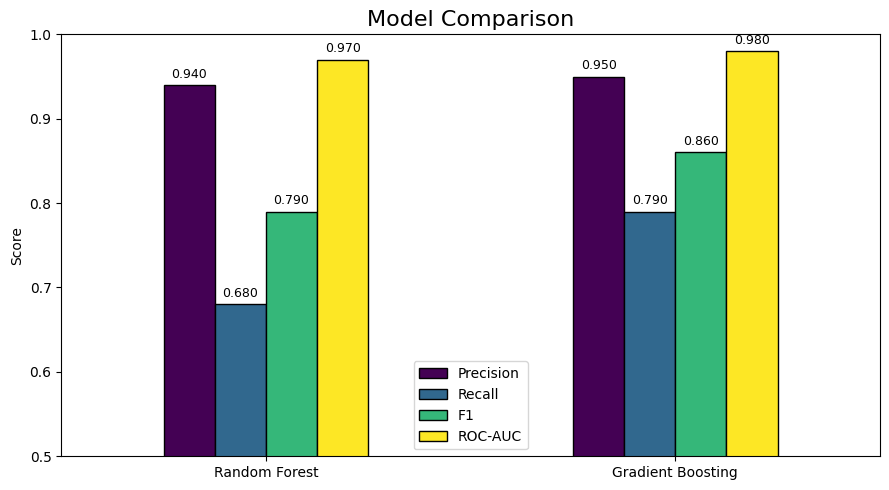

In [79]:
result.index = ["Random Forest", "Gradient Boosting"]

ax = result.plot(kind="bar",
                 figsize=(9,5),
                 colormap="viridis",
                 edgecolor="black")

for container in ax.containers:
  ax.bar_label(
      container,
      fmt="%.3f",
      fontsize=9,
      padding=3,
      rotation=0,  # Ubah rotasi angka jika diperlukan (misal: 90)
  )

plt.ylabel("Score")
plt.ylim(0.5, 1)
plt.title("Model Comparison", fontsize=16)
plt.xticks(rotation=0)
plt.tight_layout()
plt.show()

**Interpretasi:**

Berikut adalah interpretasi sederhana dari grafik perbandingan model di atas:

* **Pemenang Jelas (Gradient Boosting):**
  - Model **Gradient Boosting** unggul di hampir semua metrik evaluasi dibandingkan *Random Forest*.


* **Recall Lebih Tinggi:**
  - Gradient Boosting memiliki skor *Recall* yang lebih baik (**0.790** berbanding **0.680** milik Random Forest), yang berarti model ini jauh lebih handal dalam meminimalkan mesin rusak yang terlewat (*False Negative*).


* **Performa Keseluruhan:**
  - Metrik lain seperti *Precision* (0.950 vs 0.940), *F1-Score* (0.860 vs 0.790), dan *ROC-AUC* (0.980 vs 0.970) juga menunjukkan bahwa Gradient Boosting memberikan hasil yang lebih unggul secara konsisten untuk kebutuhan *Predictive Maintenance*.


### Confusion Matrix & Classification Report

In [80]:
best_model = result['F1'].idxmax()
best_model = rf if best_model == "Random Forest" else gb
print(f"Model terbaik: {best_model}")

Model terbaik: GradientBoostingClassifier(n_estimators=300, random_state=42)


In [81]:
y_pred = best_model.predict(X_test_scaled)

In [82]:
con_mat = confusion_matrix(y_test, y_pred)
con_mat

array([[1929,    3],
       [  14,   54]])

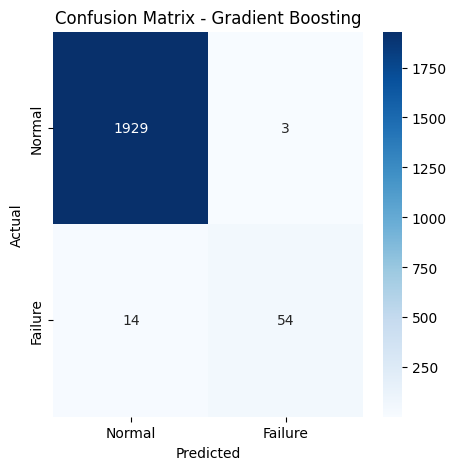

In [85]:
plt.figure(figsize=(5,5))

sns.heatmap(con_mat,
            annot=True, fmt="d", cmap="Blues",
            xticklabels=["Normal", "Failure"],
            yticklabels=["Normal", "Failure"])

plt.title("Confusion Matrix - Gradient Boosting", fontsize=12)
plt.xlabel("Predicted")
plt.ylabel("Actual")
plt.show()

**Interpretasi:**

Berikut adalah interpretasi sederhana dari **Confusion Matrix - Gradient Boosting** di atas:

* **True Negative (1.929):**
  - Ada 1.929 mesin normal yang **berhasil diprediksi dengan benar** sebagai normal.


* **False Positive (3):**
  - Hanya ada 3 mesin normal yang **salah diprediksi** sebagai gagal (False Positive sangat kecil, sehingga biaya inspeksi ekstra sangat efisien).


* **False Negative (14):**
  - Ada 14 mesin yang sebenarnya gagal tetapi **lolos dari deteksi** dan diprediksi normal. Angka inilah yang menjadi perhatian utama kita, namun sudah diminimalkan sekecil mungkin.


* **True Positive (54):**
  - Ada 54 mesin rusak yang **berhasil dideteksi dengan tepat** oleh model sebelum terjadi malapetaka.

In [86]:
print(classification_report(y_test, y_pred, target_names=["Normal", "Gagal"]))

              precision    recall  f1-score   support

      Normal       0.99      1.00      1.00      1932
       Gagal       0.95      0.79      0.86        68

    accuracy                           0.99      2000
   macro avg       0.97      0.90      0.93      2000
weighted avg       0.99      0.99      0.99      2000



Berikut adalah interpretasi sederhana dan lugas dari laporan klasifikasi (*Classification Report*) diatas:

* **Kelas Normal (Mesin Sehat):**
  - Memiliki performa yang hampir sempurna dengan *Precision* **0.99** dan *Recall* **1.00**. Ini berarti model sangat handal dan hampir tidak pernah salah mengenali mesin yang berjalan normal.

* **Kelas Gagal (Target Prioritas):**
  - **Precision (0.95):** Dari semua mesin yang diprediksi oleh model akan mengalami kerusakan, **95% benar-benar terbukti rusak**. Ini menunjukkan angka *False Positive* (salah deteksi) sangat rendah, sehingga biaya inspeksi oleh teknisi jadi sangat efisien.
  - **Recall (0.79):** Dari total 68 mesin yang sebenarnya rusak di data uji, model berhasil mendeteksi **79%** di antaranya (sekitar 54 mesin sesuai *confusion matrix* sebelumnya), sementara sekitar 21% sisanya terlewat.


* **Akurasi Keseluruhan (Accuracy 0.99):**
  - Meskipun akurasi mentahnya terlihat sangat tinggi (99%), fokus utama kita tetap pada keseimbangan *Precision* dan *Recall* pada kelas **Gagal** guna memastikan sebagian besar potensi kerusakan mesin berhasil diantisipasi sebelum memicu *downtime*.

### Curve ROC

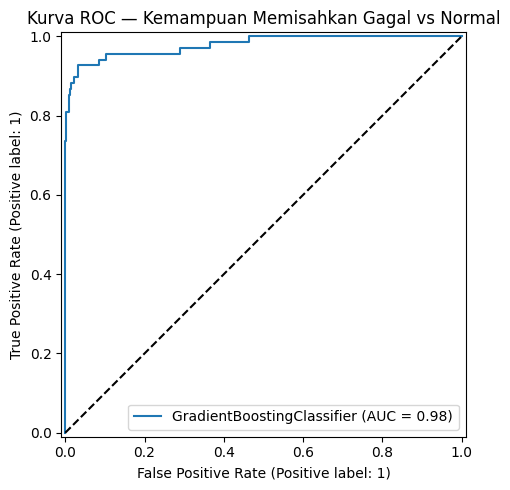

In [88]:
fig, ax = plt.subplots(figsize=(5,5))

RocCurveDisplay.from_estimator(best_model,
                               X_test_scaled,
                               y_test,
                               ax=ax)

ax.plot([0, 1], [0, 1], "k--", label="Tebak acak")
ax.set_title("Kurva ROC — Kemampuan Memisahkan Gagal vs Normal")
plt.tight_layout()
plt.show()

**Interpretasi:**

Berikut adalah interpretasi sederhana dari grafik **Kurva ROC (Receiver Operating Characteristic)** di atas:

* **AUC = 0.98 (Sangat Istimewa):**
  - Nilai Area Under Curve (AUC) sebesar 0.98 menunjukkan bahwa model *Gradient Boosting* memiliki kemampuan diskriminasi yang **sangat kuat dan luar biasa** dalam membedakan antara mesin yang normal dan mesin yang akan gagal.


* **Posisi Kurva Menanjak Tajam:**
  - Garis biru melesat dengan sangat cepat ke pojok kiri atas (mendekati *True Positive Rate* 1.0 pada *False Positive Rate* yang mendekati 0). Ini membuktikan bahwa model mampu menangkap sebagian besar kasus kegagalan dengan tingkat kesalahan (*False Positive*) yang ditekan seminim mungkin.


* **Jauh dari Garis Acak:**
  - Garis putus-putus hitam diagonal melambangkan tebakan acak (AUC = 0.5). Kurva biru kita berada jauh di atas garis tersebut, menandakan model bekerja jauh melampaui tebakan acak.



---


## Feature Importance

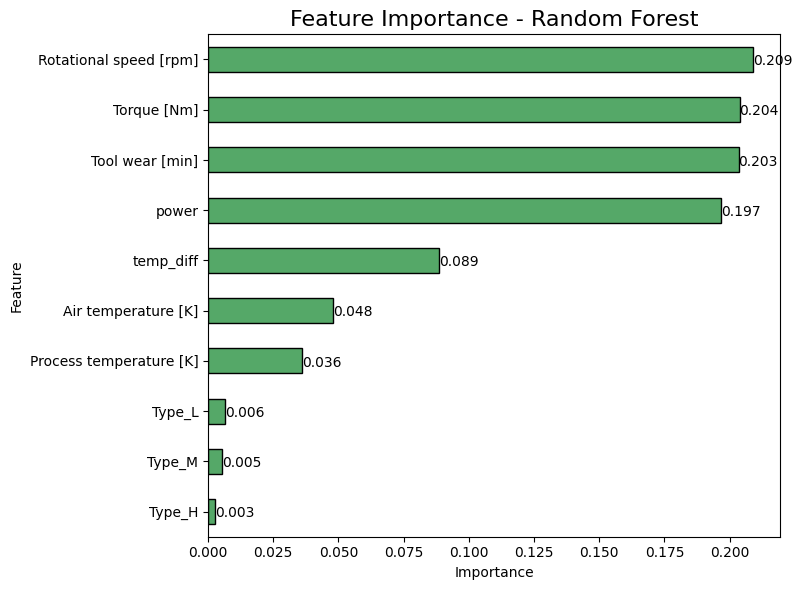

In [98]:
# Ambil feature importance menggunakan atribut yang benar yaitu feature_importances_
imp_feat = pd.Series(rf.feature_importances_, index=X.columns).sort_values()

# Visualisasikan hasilnya
plt.figure(figsize=(8,6))
ax = imp_feat.plot(kind="barh",
                   color="#55A868",
                   edgecolor="black")

plt.title("Feature Importance - Random Forest", fontsize=16)
plt.xlabel("Importance")
plt.ylabel("Feature")
plt.tight_layout()
for i in ax.patches:
    ax.annotate(f"{i.get_width():.3f}",
                (i.get_x() + i.get_width(), i.get_y()),
                size=10, xytext=(0, 5),
                textcoords="offset points")
plt.show()

**Interpretasi:**


Berikut adalah interpretasi sederhana dari grafik **Feature Importance - Random Forest** di atas:

* **Empat Faktor Utama (Paling Menentukan):**
  - Fitur **`Rotational speed [rpm]`** (0.209), **`Torque [Nm]`** (0.204), **`Tool wear [min]`** (0.203), dan fitur buatan **`power`** (0.197) memiliki tingkat kepentingan tertinggi dan hampir setara. Ini berarti model sangat mengandalkan parameter kecepatan putar, torsi beban, durasi keausan alat, serta daya mekanik mesin untuk mendeteksi risiko kegagalan.

* **Faktor Menengah (Pendukung Suhu):**
  - **`temp_diff`** (0.089), **`Air temperature [K]`** (0.048), dan **`Process temperature [K]`** (0.036) berada di tingkat menengah. Selisih suhu dan suhu operasional tetap diperhitungkan, namun pengaruhnya tidak sebesar beban mekanik dan keausan alat.

* **Faktor Paling Kecil:**
  - Kategori tipe produk (**`Type_L`**, **`Type_M`**, dan **`Type_H`**) memiliki skor kepentingan yang sangat kecil (mendekati 0). Artinya, jenis kualitas mesin hampir tidak menjadi penentu utama bagi model dalam memprediksi kerusakan dibandingkan kondisi sensor fisik secara *real-time*.

## Insight & Conclusion

### **Kesimpulan Utama & Rekomendasi Bisnis**

Berdasarkan seluruh proses analisis mulai dari Exploratory Data Analysis (EDA), rekayasa fitur (*feature engineering*), hingga evaluasi model, berikut adalah poin-poin penting yang dapat disimpulkan:

#### **1. Karakteristik Data & Masalah Imbalance**
* Kasus kegagalan mesin (*failure*) tergolong **sangat langka**, yaitu hanya **3.39%** (339 mesin rusak dari total 10.000 data).
* Ketidakseimbangan data yang ekstrem ini berhasil diatasi dengan menggunakan stratifikasi saat membagi data (*train-test split*) dan menerapkan parameter `class_weight='balanced'` pada model machine learning agar model tetap sensitif terhadap kelas minoritas (mesin gagal).

#### **2. Efektivitas Rekayasa Fitur (Feature Engineering)**
* Pembuatan fitur **`power`** (daya mekanik) terbukti sangat krusial karena berhasil menempati posisi ke-4 fitur paling berpengaruh dalam model Random Forest dengan nilai kepentingan **19.7%**.
* Selisih suhu antara proses dan udara sekitar (**`temp_diff`**) juga memberikan kontribusi sebesar **8.9%**.

#### **3. Evaluasi Performa Model (Mengapa Gradient Boosting Unggul?)**
* Dalam skenario *Predictive Maintenance*, tujuan utama kita adalah meminimalkan **False Negative (FN)** (mesin diprediksi normal padahal sebenarnya akan rusak mendadak) guna menekan biaya perbaikan darurat (*downtime*) yang sangat mahal. Oleh karena itu, kita memprioritaskan metrik **Recall**.
* **Gradient Boosting** terpilih sebagai model terbaik dengan performa unggul:
  - **Recall Kelas Gagal: 0.79 (79%)** (mampu menangkap 54 dari 68 mesin rusak di data uji, berbanding jauh dengan Random Forest yang hanya 68%).
  - **Precision Kelas Gagal: 0.95 (95%)** (hanya menghasilkan 3 kesalahan *False Positive*, sehingga meminimalkan inspeksi palsu oleh teknisi).
  - **ROC-AUC: 0.98**, menunjukkan kemampuan pemisahan kelas yang hampir sempurna.

#### **4. Rekomendasi Aksi untuk Operasional Pabrik**
* **Fokus pada 3 Sensor Utama:** Karena `Rotational speed`, `Torque`, dan `Tool wear` memiliki total akumulasi kepentingan sebesar **~61%**, tim pemeliharaan harus memasang alarm otomatis jika parameter sensor ini melewati ambang batas aman.
* **Manajemen Keausan Alat (Tool Wear):** Alat pemotong sebaiknya diganti secara terjadwal mendekati batas akumulasi waktu optimal sebelum mencapai puncak degradasi (~200 menit).
* **Pemantauan Daya:** Integrasikan kalkulasi fitur `power` secara *real-time* di dasbor pemantauan mesin untuk mendeteksi lonjakan daya mekanis abnormal secara dini.